In [1]:
from src.datasets.factory import get_dataset
from src.models.bandits import (
    ContextualGPTS,
    ContextualLinTS,
    ContextualLinUCB,
    DecayingEpsilonGreedyBandit,
    EpsilonGreedyBandit,
    RandomBandit,
)
from src.models.reward import get_conversion_reward, get_item_reward
from src.utils.eval_helpers import plot_bandit_performances

Do not forget to run `gcloud auth application-default login` in your terminal !

# A. Synthetic Dataset : Direct link between history and conversion

On construit un **dataset** pour lequel les historiques de reservation des utilisateurs (total et labels des catégories, sous catégories, venue type et venue ids distinct dans l'historique de nos utilisateurs) sont **cohérents avec nos données réelles**.

Avec ```generate_user_history```;
**La taille de l'historique des utilisateurs** (le nombre de catégories, sous catégories, venue type et venue ids distinct) suit une loi de Weibull discrétisée $\forall x \geq 0,~ f(x;k, \lambda) = \frac{k}{\lambda} \cdot \left (\frac{x}{\lambda}\right)^{k-1} e^{-\left (\frac{x}{\lambda}\right)^{k}}$.

<p align="center">
<img src="../documentation/PlaygroundDataset.png" width="60%">
</p>

**Le contenu de l'historique des utilisateurs** suit une loi de probabilités caractérisée par le total des réservations dans chaque catégorie, sous catégories et venue type entre le 01/02/2026 et 01/04/2026.

La conversion (outcome de la recommendation, ie est ce que l'utilisateur a clické/mis en favori/reservé) est calculé par un tirage stochastique depend d'un probabilité de conversion $p$ calculée par : 

```
p_click = 0.02
if item.cat in user_history["cats"]:
    p_click += 0.05
if item.sub in user_history["subs"]:
    p_click += 0.12
if item.vt in user_history["venue_types"]:
    p_click += 0.08

p_faved = 0.3 * p_click
p_booked = 0.1 * p_click
```

In [ ]:
pg_dataset = get_dataset("playground_dataset")

pg_dataset.training_data = pg_dataset.generate_synthetic_training_dataset(
    num_user=80000
)
pg_dataset.training_data = pg_dataset.add_vectorized_history(pg_dataset.training_data)

## 1. Non contextual MABs

2026-07-30 18:07:07 | INFO | src.models.bandits.bandit | Training RandomBandit (mode: classic)...
100%|██████████| 80000/80000 [00:07<00:00, 11189.44it/s]
2026-07-30 18:07:15 | INFO | src.models.bandits.bandit | Bandit training completed.
2026-07-30 18:07:15 | INFO | src.models.bandits.bandit | Training EpsilonGreedyBandit (mode: classic)...
100%|██████████| 80000/80000 [00:03<00:00, 23595.65it/s]
2026-07-30 18:07:19 | INFO | src.models.bandits.bandit | Bandit training completed.
2026-07-30 18:07:19 | INFO | src.models.bandits.bandit | Training DecayingEpsilonGreedyBandit (mode: classic)...
100%|██████████| 80000/80000 [00:03<00:00, 25312.54it/s]
2026-07-30 18:07:22 | INFO | src.models.bandits.bandit | Bandit training completed.


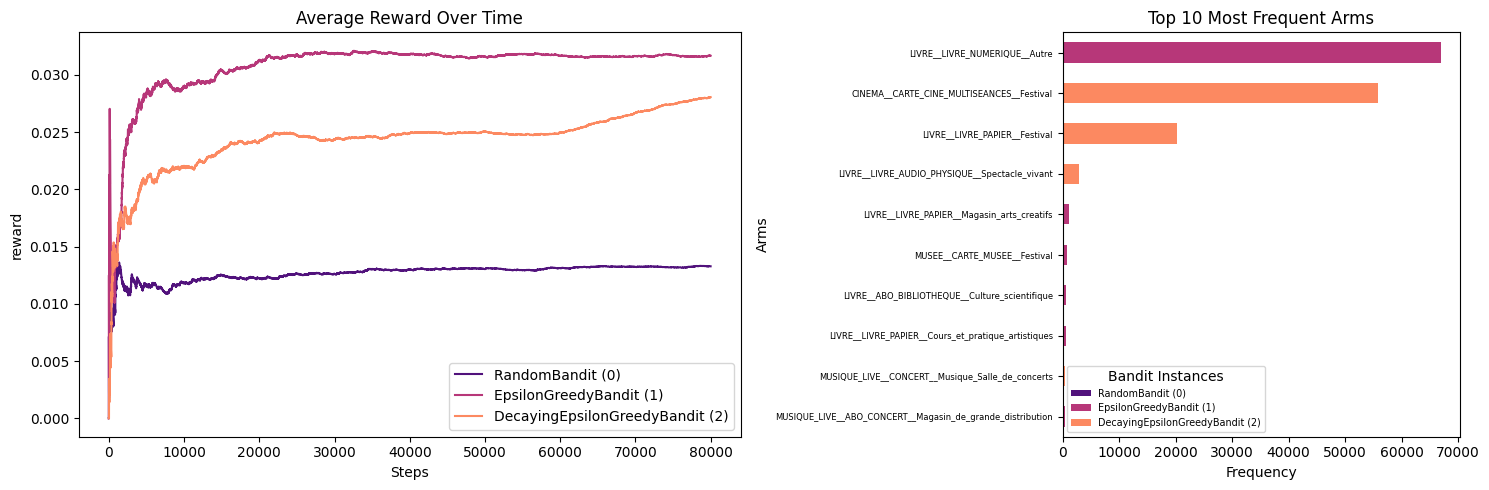

In [3]:
bandits = []
baseline_bandit = RandomBandit()
baseline_bandit.train(dataset=pg_dataset, reward_func=get_conversion_reward)
bandits.append(baseline_bandit)

epsilon_greedy_bandit = EpsilonGreedyBandit(epsilon=0.1)
epsilon_greedy_bandit.train(dataset=pg_dataset, reward_func=get_conversion_reward)
bandits.append(epsilon_greedy_bandit)

decaying_epsilon_greedy_bandit = DecayingEpsilonGreedyBandit(
    initial_epsilon=1.0,
    decay_rate=0.99,
    min_epsilon=0.01,
)
decaying_epsilon_greedy_bandit.train(
    dataset=pg_dataset, reward_func=get_conversion_reward
)
bandits.append(decaying_epsilon_greedy_bandit)

plot_bandit_performances(bandits)

Le graphique de gauche represente le reward moyen cumulé de chaque bandit. Pour un step T, la valeur en ordonnée correspond à $\frac{1}{T} \sum_{t = 1}^T r_t$. <br>
Sur le plot, on cherche à voir : 
- Au début (phase d'exploration) : La courbe oscille beaucoup et est généralement basse mais peut presenter des pics important : si le bandit décroche un reward important au début de son training, il n'est pas pondéré par un nombre iportant de steps comme c'est la cas plus tard .L'algorithme teste des bras potentiellement sous-optimaux pour accumuler de l'information.
- À la fin (phase d'exploitation) : Si l'algorithme est bon, la courbe doit se stabiliser et tendre vers une asymptote, se rapprochant de la valeur de récompense théorique du meilleur bras possible.

Le graphique de droite represente lui les bras les plus choisis par chaque bandit. Pour des bandits non contextuels comme ici, quelques bras concentrent l'immense majorité des selections.

## 2. Contextual MABs

In [ ]:
pg_dataset.training_data = pg_dataset.training_data.head(30000)
context_bandits = []
LinUCB = ContextualLinUCB(alpha=0.02)
LinUCB.train(pg_dataset, get_conversion_reward, context="context_vec")
context_bandits.append(LinUCB)

pg_dataset.training_data = pg_dataset.training_data.head(3000)
lin_ts = ContextualLinTS(v2=0.3, d=99)
lin_ts.train(pg_dataset, get_conversion_reward, context="context_vec")
context_bandits.append(lin_ts)

gpts = ContextualGPTS(max_memory=2000)
gpts.train(pg_dataset, get_conversion_reward, context="context_vec")
context_bandits.append(gpts)

plot_bandit_performances(context_bandits)

Comme precedement, on voit que le LinUCB converge. On remarque une diversité bien plus prononcée sur le choix des bras, ce qui correspond à l'architecture contextuelle des bandits consideres ici.<br>
On remarque aussi que les bras les plus choisis correspondent globalement aux catégories les plus populaires.

# B. Oracle Model : Concrete results with Offline Training

On s'interesse maintenant au dataset utilisant des données d'utilisateurs réels. L'entrainement des Bandits suit les étapes suivantes : <br>

**Pour un utilisateur $u$ à une étape $t$ donnée :**

### Étape 1 : Définition du contexte

L'utilisateur $u$ est caractérisé par deux éléments :

* Un vecteur d'embedding $\mathbf{x}_u \in \mathbb{R}^d$
* Un historique d'interactions $h_u$, contenant les métadonnées avec lesquelles il a déjà interagi : $h_u = \{C_u, S_u, V_u\}$ (catégories, sous-catégories, types de lieux).

### Étape 2 : L'Espace d'Action et le Filtrage (Le choix du Bras)

Le bandit choisit un bras $a = (\text{cat}_a, \text{sub}_a, \text{lt}_a)$ parmi l'ensemble des bras possibles $\mathcal{A}$, restreignant le catalogue total d'items $\mathcal{I}$ à un sous-ensemble d'items éligibles $\mathcal{I}_a \subset \mathcal{I}$ :


$$\mathcal{I}_a = \{i \in \mathcal{I} \mid \text{cat}_i = \text{cat}_a \land \text{sub}_i = \text{sub}_a \land \text{vt}_i = \text{vt}_a\}$$

### Étape 3 : La Sélection de l'Item par le Système (Retrieval)

On effectue une recherche du plus proche voisin (Top-1) dans la table LanceDB en utilisant la métrique du produit scalaire (dot product). <br>
L'item sélectionné $i^*$ est celui qui minimise la distance géométrique $\text{dist}(\mathbf{x}_u, \mathbf{y}_i)$ avec l'embedding de l'utilisateur pour le sous ensemble $\mathcal{I}_a$ :


$$i^*(a, u) = \arg\min_{i \in \mathcal{I}_a} \text{dist}(\mathbf{x}_u, \mathbf{y}_i)$$


### Étape 4 : L'Évaluation de la Probabilité de Conversion (L'Oracle)

Soit $x = \text{dist}(\mathbf{x}_u, \mathbf{y}_{i^*(a, u)})$. Les probabilités intrinsèques de chaque événement sont calculées via des fonctions exponentielles $f_e(x)$ (où $e \in \{\text{click}, \text{fave}, \text{book}\}$) : $$f_e(x) = f(x; k_e, \alpha_e, \beta_e) = k_e \cdot e^{-\alpha_e x} + \beta_e$$
Les paramètres de ces fonctions sont calculées à partir des logs du Two Tower, qui permettent d'estimer des probabilités de conversion pour des distances données. Lees fonctions obtenues sont (ou sont proches de):

<p align="center">
<img src="../documentation/TTMapping.png" width="60%">
</p>

On tient compte du `boost` et de la condition de cascade (pas de favori ni de réservation sans clic), les probabilités réelles (espérances) d'activation de chaque événement pour le bras $a$ sont :

* **Clic :** $P(\text{clicked} \mid u, a) = \min\left(1, \text{boost} \cdot f_{\text{clicked}}(x)\right)$
* **Favoris :** $P(\text{faved} \mid u, a) = \min\left(1, \text{boost} \cdot f_{\text{faved}}(x)\right) \cdot P(\text{clicked} \mid u, a)$
* **Réservation :** $P(\text{booked} \mid u, a) = \min\left(1, \text{boost} \cdot f_{\text{booked}}(x)\right) \cdot P(\text{clicked} \mid u, a)$

### Étape 5 : Évaluation Stochastique de l'Outcome et Reward

Pour chaque événement;
* On a $p_{event} = P(\text{event} \mid u, a)$
* On effectue un tirage aléatoire $x_{event} \in [0, 1]$ 

On a alors :
$$\text{Outcome}_{event} = \mathbb{1}_{\{x < p_{event}\}}(x_{event})$$

On évalue le reward : $$\text{Reward}(h_u, \text{Outcome}, \text{arm}) = R_{\text{conv}}(\text{Outcome}) \cdot \Big(1 + \alpha \cdot R_{\text{diversité}}(h_u, a)\Big) $$


In [ ]:
tt_dataset = get_dataset("tt_based_dataset")

tt_dataset.training_data = tt_dataset.user_data.head(1000)

## 1. Convertion Probabilities

### Conversion only reward

2026-06-25 17:08:43 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:50<00:00, 19.80it/s]
2026-06-25 17:09:34 | INFO | src.models.bandits | Bandit training completed.
2026-06-25 17:09:34 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:50<00:00, 19.67it/s]
2026-06-25 17:10:24 | INFO | src.models.bandits | Bandit training completed.
2026-06-25 17:10:24 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:50<00:00, 19.88it/s]
2026-06-25 17:11:15 | INFO | src.models.bandits | Bandit training completed.


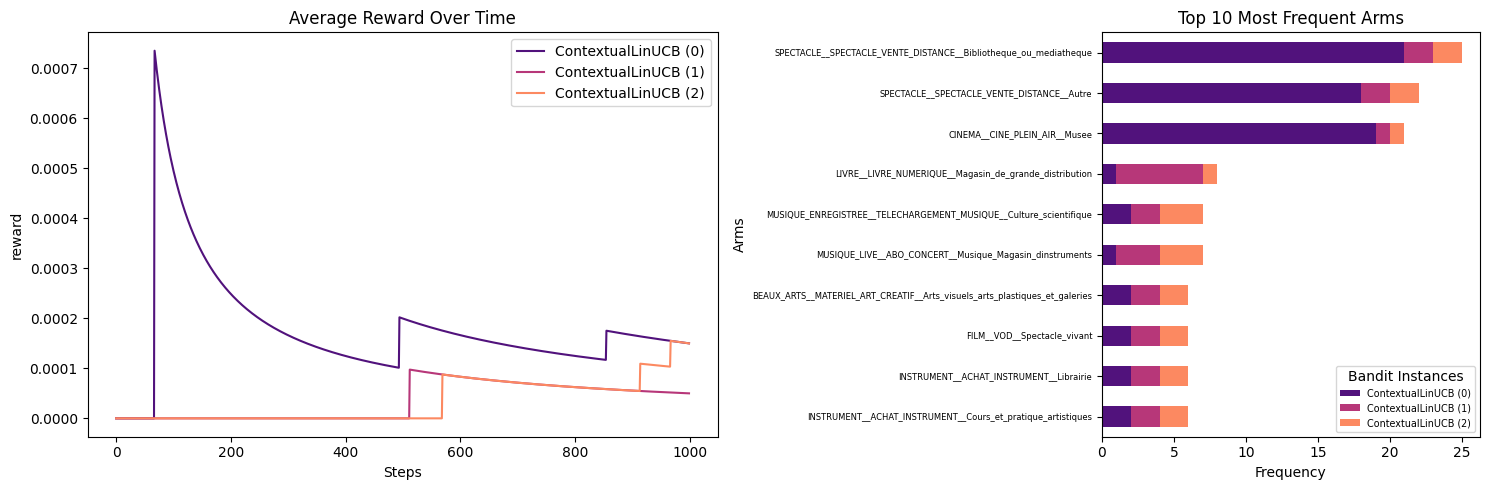

In [ ]:
bandits = []
for a in [0.02, 0.1, 0.3]:
    LinUCB = ContextualLinUCB(alpha=a)
    LinUCB.train(tt_dataset, get_conversion_reward, context="user_embedding")
    bandits.append(LinUCB)

plot_bandit_performances(bandits)

On observe de très rares gains: les probabilités de conversion sont faibles, et la plupart des decisions du bandit amènent un reward nul, qu'il choisisse le bras optimal ou non. Les bras choisis sont assez divers et ne correspondent pas au catégories les plus populaires.

### Conversion and diversity reward

2026-06-25 17:11:15 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:48<00:00, 20.65it/s]
2026-06-25 17:12:03 | INFO | src.models.bandits | Bandit training completed.
2026-06-25 17:12:03 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:52<00:00, 18.99it/s]
2026-06-25 17:12:56 | INFO | src.models.bandits | Bandit training completed.
2026-06-25 17:12:56 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:53<00:00, 18.72it/s]
2026-06-25 17:13:49 | INFO | src.models.bandits | Bandit training completed.


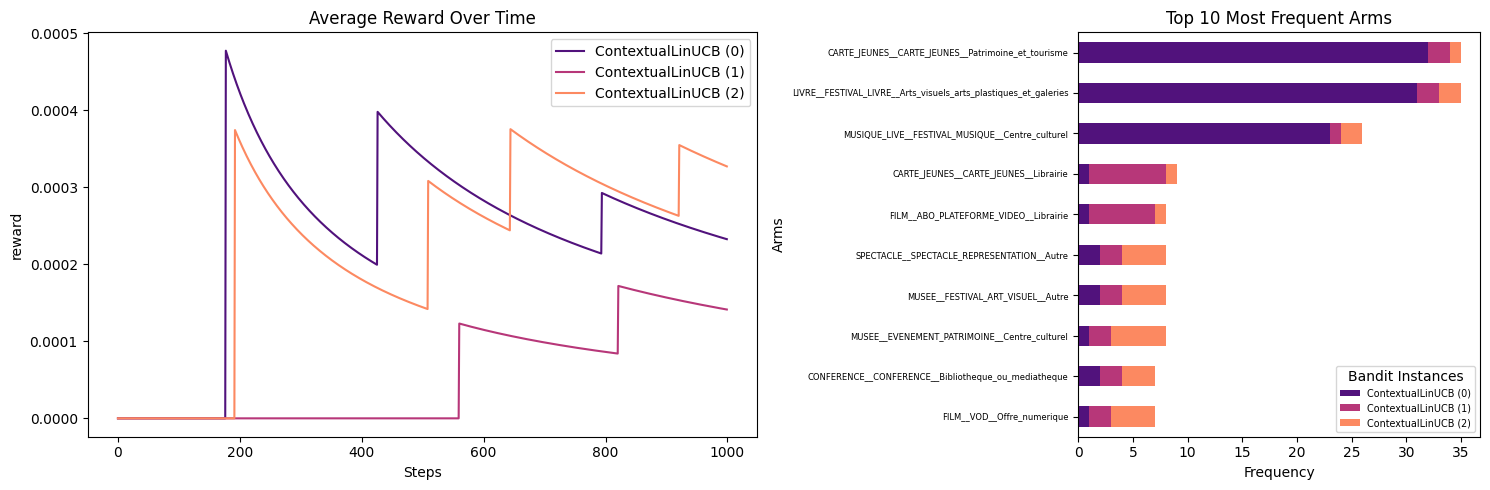

In [ ]:
div_bandits = []
for a in [0.02, 0.1, 0.3]:
    LinUCB = ContextualLinUCB(alpha=a)
    LinUCB.train(tt_dataset, get_item_reward, context="user_embedding")
    div_bandits.append(LinUCB)

plot_bandit_performances(div_bandits)

Mêmes observations. Logique car le reward complet vaut : $$Reward = Conversion \cdot ( 1 + \beta \cdot Diversité)$$
Ce comportement correspond à un choix de ne pas recompenser les MABs pour un gain en diversité si il n'est pas directement lié à une conversion.

### **Boosted conversion probabilities**

On veut voir si les MABs sont capables de converger dans les bonnes conditions. On va gonfler artificiellement les probabilités de conversion.

2026-06-26 13:59:23 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [00:50<00:00, 19.96it/s]
2026-06-26 14:00:13 | INFO | src.models.bandits | Bandit training completed.


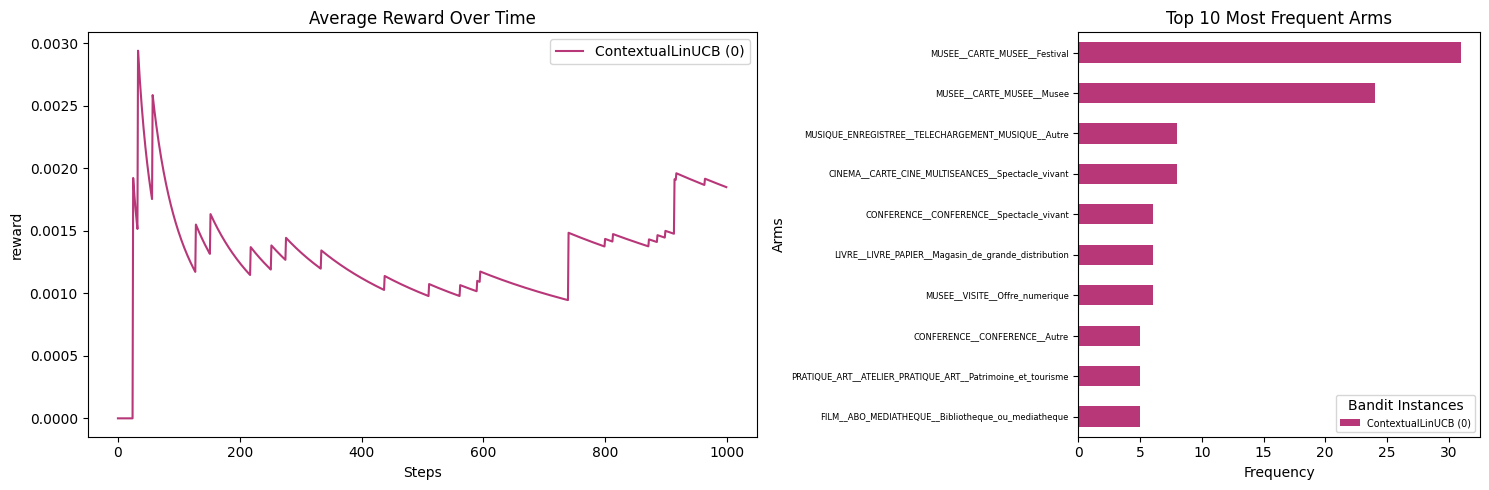

In [ ]:
boost_LinUCB = ContextualLinUCB(alpha=0.1, boost=10)
boost_LinUCB.train(tt_dataset, get_conversion_reward, context="user_embedding")
plot_bandit_performances([boost_LinUCB])

In [ ]:
boost_LinUCB.evaluate_bandit(tt_dataset, context="user_embedding", len_eval=1000)

2026-06-26 14:00:13 | INFO | src.models.bandits | Evaluating ContextualLinUCB...
100%|██████████| 1000/1000 [00:00<00:00, 2713.90it/s]
2026-06-26 14:00:14 | INFO | src.models.bandits | Bandit evaluation completed.


,chosen_arm,count
72,MUSEE__CARTE_MUSEE__Musee,39
117,MUSIQUE_LIVE__EVENEMENT_MUSIQUE__Librairie,37
14,CINEMA__SEANCE_CINE__Centre_culturel,37
5,CINEMA__CINE_PLEIN_AIR__Arts_visuels_arts_plas...,36
68,MEDIA__APP_CULTURELLE__Spectacle_vivant,31
...,...,...
53,JEU__JEU_EN_LIGNE__Librairie,1
52,JEU__JEU_EN_LIGNE__Culture_scientifique,1
46,JEU__ESCAPE_GAME__Centre_culturel,1
45,JEU__ESCAPE_GAME__Bibliotheque_ou_mediatheque,1


2026-06-26 14:00:14 | INFO | src.models.bandits | Training ContextualLinUCB (mode: classic)...
100%|██████████| 1000/1000 [00:50<00:00, 19.66it/s]
2026-06-26 14:01:04 | INFO | src.models.bandits | Bandit training completed.


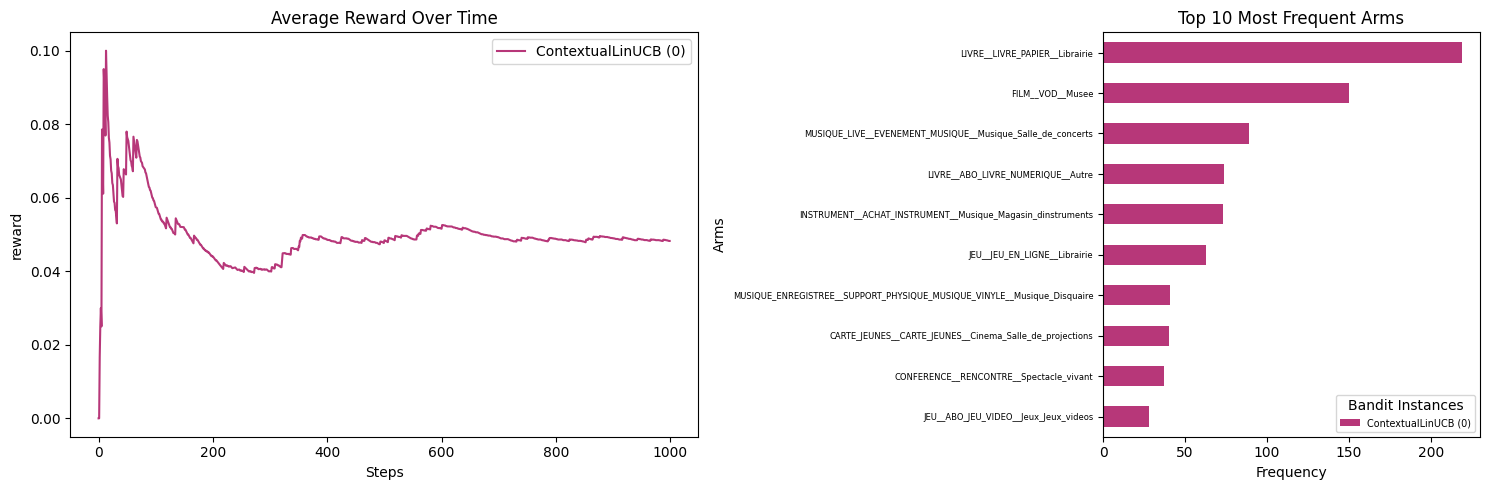

In [ ]:
boost_LinUCB = ContextualLinUCB(alpha=0.1, boost=100)
boost_LinUCB.train(tt_dataset, get_conversion_reward, context="user_embedding")
plot_bandit_performances([boost_LinUCB])

In [ ]:
boost_LinUCB.evaluate_bandit(tt_dataset, context="user_embedding", len_eval=1000)

2026-06-26 14:01:05 | INFO | src.models.bandits | Evaluating ContextualLinUCB...
100%|██████████| 1000/1000 [00:00<00:00, 3435.75it/s]
2026-06-26 14:01:05 | INFO | src.models.bandits | Bandit evaluation completed.


,chosen_arm,count
14,LIVRE__LIVRE_PAPIER__Librairie,193
16,MUSIQUE_ENREGISTREE__SUPPORT_PHYSIQUE_MUSIQUE_...,156
1,CARTE_JEUNES__CARTE_JEUNES__Cinema_Salle_de_pr...,150
3,CONFERENCE__RENCONTRE__Magasin_de_grande_distr...,94
10,LIVRE__ABO_LIVRE_NUMERIQUE__Autre,84
13,LIVRE__LIVRE_PAPIER__Festival,73
12,LIVRE__LIVRE_NUMERIQUE__Autre,70
6,FILM__VOD__Musee,66
15,MEDIA__PODCAST__Patrimoine_et_tourisme,32
7,INSTRUMENT__ACHAT_INSTRUMENT__Musique_Magasin_...,30


## 2. Regret and Reward Target

Pour un utilisateur unique $u$ à une étape $t$ donnée :

- **Étape 1 : Contexte** : L'utilisateur $u$ est caractérisé par son vecteur d'embedding $\mathbf{x}_u \in \mathbb{R}^d$ et son historique d'interactions $h_u = \{C_u, S_u, V_u\}$ (catégories, sous-catégories, types de lieux).

- **Étape 2 : Choix du bras (Bandit)** : Le bandit choisit un bras $a = (\text{cat}_a, \text{sub}_a, \text{lt}_a) \in \mathcal{A}$, restreignant le catalogue d'items à $\mathcal{I}_a = \{i \in \mathcal{I} \mid \text{cat}_i = \text{cat}_a \land \text{sub}_i = \text{sub}_a \land \text{lt}_i = \text{lt}_a\}$

- **Étape 3 : Choix de l'Item (Retrieval)** : On effectue un retrieval Top-1 ($k=1$) dans LanceDB pour trouver l'item le plus proche $i^*(a, u) = \arg\min_{i \in \mathcal{I}_a} \text{dist}(\mathbf{x}_u, \mathbf{y}_i)$

- **Étape 4 : Probabilité de Conversion (Oracle)** : Pour $x = \text{dist}(\mathbf{x}_u, \mathbf{y}_{i^*(a, u)})$, la probabilité de conversion est $P(\text{event} \mid u, a) = \min\left(1, \text{boost} \cdot f_{\text{event}}(x)\right)$


### **Étape 5 : Espérance maximale du Reward** :

L'espérance de la récompense de conversion pure, $\mathbb{E}[R_{\text{conv}}(u, a)]$, est la somme pondérée de ces probabilités par leurs poids respectifs $\omega$ :

$$\mathbb{E}[R_{\text{conv}}(u, a)] = \frac{\omega_1 \cdot P(\text{clicked} \mid u, a) + \omega_2 \cdot P(\text{faved} \mid u, a) + \omega_3 \cdot P(\text{booked} \mid u, a)}{\omega_1 + \omega_2 + \omega_3}$$

En y injectant le multiplicateur de diversité $D(h_u, a)$, la récompense maximale attendue $\mu^*(u)$ par l'Oracle pour un utilisateur $u$ est :

$$\mu^*(u) = \max_{a \in \mathcal{A}} \left( \mathbb{E}[R_{\text{conv}}(u, a)] \cdot \Big(1 + \beta \cdot D(h_u, a)\Big) \right)$$

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from src.datasets.tt_based_dataset.oracle_baseline import (
    OracleBaselineCalculator,
)

tt_dataset.training_data = tt_dataset.user_data.head(500)

oracle_boost_conv = OracleBaselineCalculator(
    table=tt_dataset.table,
    all_possible_arms=tt_dataset.all_possible_arms,
    TT_score_mapping=tt_dataset.TT_score_mapping,
    boost=100,
)
oracle_boost_conv_baseline = oracle_boost_conv.compute_dataset_baselines(
    df=tt_dataset.training_data, reward_func=get_conversion_reward
)

oracle_boost_div = OracleBaselineCalculator(
    table=tt_dataset.table,
    all_possible_arms=tt_dataset.all_possible_arms,
    TT_score_mapping=tt_dataset.TT_score_mapping,
    boost=100,
)
oracle_boost_div_baseline = oracle_boost_div.compute_dataset_baselines(
    df=tt_dataset.training_data, reward_func=get_item_reward
)

2026-06-26 14:03:36 | INFO | src.datasets.tt_based_dataset.oracle_baseline | Calcul des baselines théoriques de l'Oracle (Filtres IN/NOT IN)...


 35%|███▌      | 177/500 [01:19<02:26,  2.20it/s]2026-06-26 14:04:56 | WARNING | src.datasets.tt_based_dataset.oracle_baseline | No item found for filter categories IN ('BEAUX_ARTS') AND subcategories NOT IN ('MATERIEL_ART_CREATIF') AND venue_types NOT IN ('Librairie', 'Magasin_de_grande_distribution') and user history {'cats': array(['BEAUX_ARTS'], dtype=object), 'subs': array(['MATERIEL_ART_CREATIF'], dtype=object), 'venue_ids': array(['14405', '15156'], dtype=object), 'venue_types': array(['Librairie', 'Magasin_de_grande_distribution'], dtype=object), 'categories': array(['BEAUX_ARTS'], dtype=object), 'subcategories': array(['MATERIEL_ART_CREATIF'], dtype=object)}
2026-06-26 14:04:56 | WARNING | src.datasets.tt_based_dataset.oracle_baseline | No item found for filter categories IN ('BEAUX_ARTS') AND subcategories NOT IN ('MATERIEL_ART_CREATIF') AND venue_types IN ('Librairie', 'Magasin_de_grande_distribution') and user history {'cats': array(['BEAUX_ARTS'], dtype=object), 'subs': ar

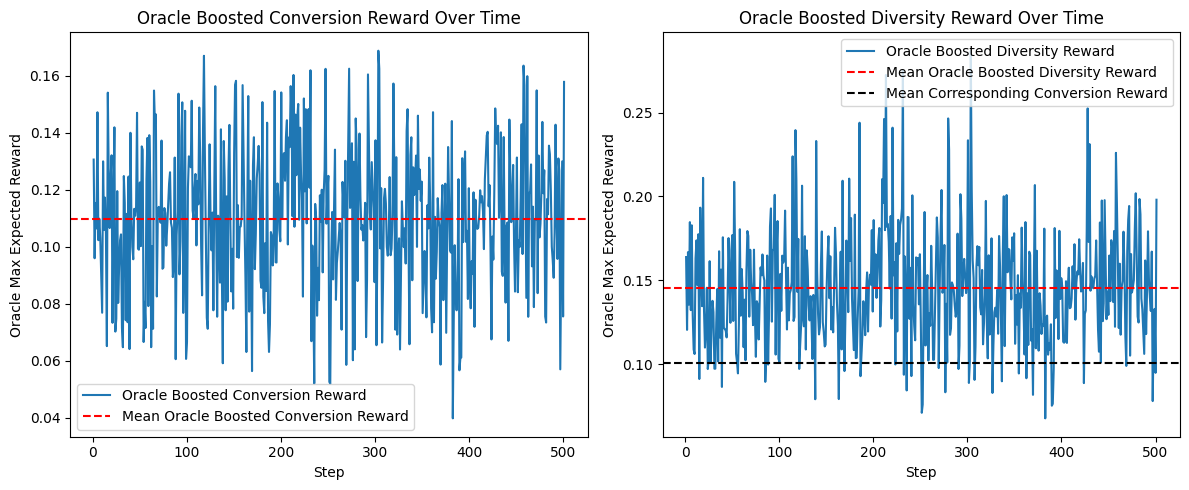

Conversion reward baseline: 0.110
Diversity reward baseline: 0.146 and corresponding conversion reward baseline: 0.100


In [ ]:
plt.subplots(1, 2, figsize=(12, 5))

x = np.linspace(1, len(tt_dataset.training_data) + 1, len(tt_dataset.training_data))
y_conv = oracle_boost_conv_baseline["oracle_expected_reward"]
z_conv = np.mean(oracle_boost_conv_baseline["oracle_expected_reward"])
y_div = oracle_boost_div_baseline["oracle_expected_reward"]
z_div = np.mean(oracle_boost_div_baseline["oracle_expected_reward"])
z_div_eq_conv = np.mean(
    [
        get_conversion_reward(x)
        for x in oracle_boost_div_baseline["oracle_conversion_probabilities"]
    ]
)

plt.subplot(1, 2, 1)
plt.plot(x, y_conv, label="Oracle Boosted Conversion Reward")
plt.axhline(
    y=z_conv, color="r", linestyle="--", label="Mean Oracle Boosted Conversion Reward"
)
plt.title("Oracle Boosted Conversion Reward Over Time")
plt.xlabel("Step")
plt.ylabel("Oracle Max Expected Reward")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(x, y_div, label="Oracle Boosted Diversity Reward")
plt.axhline(
    y=z_div, color="r", linestyle="--", label="Mean Oracle Boosted Diversity Reward"
)
plt.axhline(
    y=z_div_eq_conv,
    color="black",
    linestyle="--",
    label="Mean Corresponding Conversion Reward",
)
plt.title("Oracle Boosted Diversity Reward Over Time")
plt.xlabel("Step")
plt.ylabel("Oracle Max Expected Reward")
plt.legend()

plt.tight_layout()
plt.show()

print(f"Conversion reward baseline: {z_conv:.3f}")
print(
    f"Diversity reward baseline: {z_div:.3f} and corresponding conversion reward baseline: {z_div_eq_conv:.3f}"  # noqa: E501
)

## 3. Bandits Algorithms Comparison

In [ ]:
tt_dataset.training_data = tt_dataset.user_data.head(20000)

2026-06-22 11:27:12 | INFO | src.models.bandits | Training DecayingEpsilonGreedyBandit...
100%|██████████| 7000/7000 [05:19<00:00, 21.89it/s]
2026-06-22 11:32:32 | INFO | src.models.bandits | Bandit training completed.
2026-06-22 11:32:32 | INFO | src.models.bandits | Training ContextualLinUCB...
100%|██████████| 7000/7000 [05:50<00:00, 19.97it/s]
2026-06-22 11:38:22 | INFO | src.models.bandits | Bandit training completed.


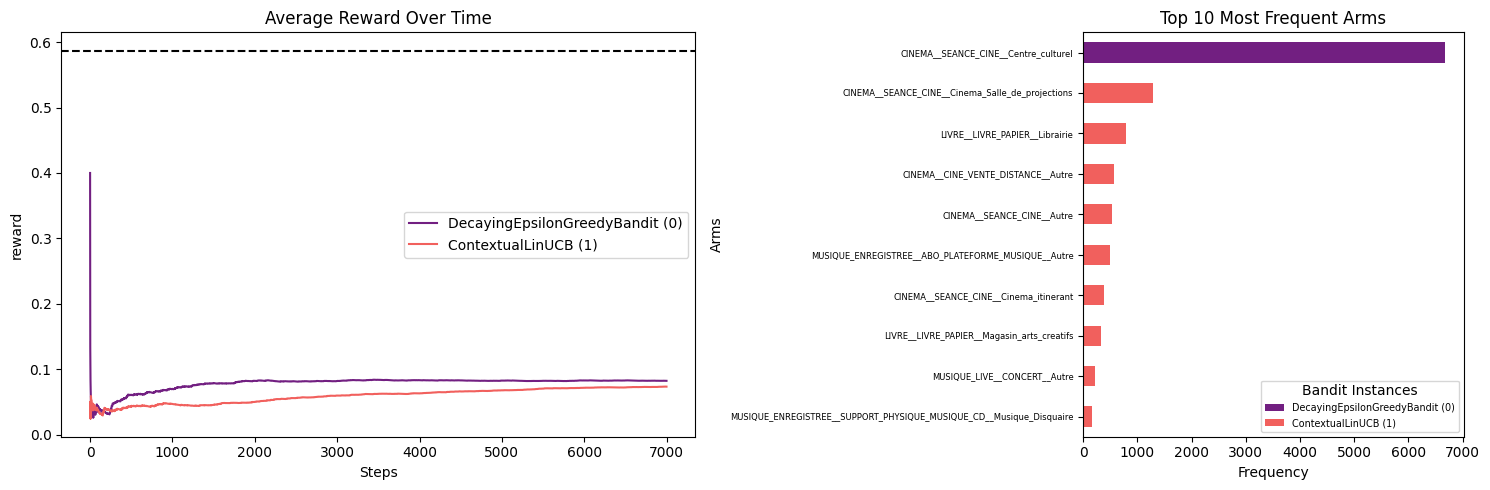

In [ ]:
boost_bandits = []

epsilon_greedy_bandit = DecayingEpsilonGreedyBandit(
    initial_epsilon=1.0, decay_rate=0.99, min_epsilon=0.01, boost=100
)
epsilon_greedy_bandit.train(dataset=tt_dataset, reward_func=get_conversion_reward)
boost_bandits.append(epsilon_greedy_bandit)

boost_LinUCB = ContextualLinUCB(alpha=0.1, boost=100)
boost_LinUCB.train(tt_dataset, get_conversion_reward, context="user_embedding")
boost_bandits.append(boost_LinUCB)

plot_bandit_performances(boost_bandits, axhline=z_conv)

Le **Decaying $\epsilon$-Greedy** converge très rapidement vers un bras unique. Une fois le plateau atteint, il propose quasi systematiquement le même bras et ne progresse plus ou presque plus. <br>
Le **LinUCB**, lui, 

In [ ]:
boost_LinTS = ContextualLinTS(v2=0.3, d=64, boost=1000)
boost_LinTS.train(tt_dataset, get_conversion_reward, context="user_embedding")
boost_bandits.append(boost_LinTS)

plot_bandit_performances(boost_bandits, axhline=z_conv)

### With diversity

2026-06-18 17:45:19 | INFO | src.models.bandits | Training ContextualLinUCB...
100%|██████████| 15000/15000 [14:42<00:00, 16.99it/s]  
2026-06-18 18:00:01 | INFO | src.models.bandits | Bandit training completed.


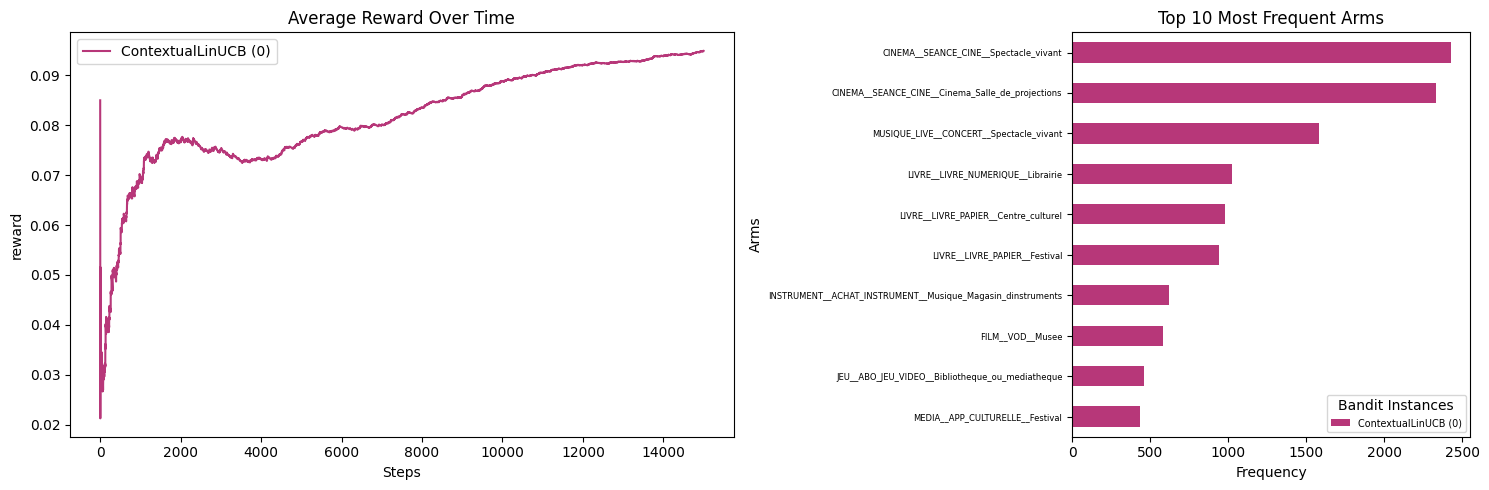

In [ ]:
boost_div_LinUCB = ContextualLinUCB(alpha=0.1, boost=100)
boost_div_LinUCB.train(tt_dataset, get_item_reward, context="user_embedding")
plot_bandit_performances([boost_div_LinUCB])

### Long Run

2026-06-18 18:00:02 | INFO | src.models.bandits | Training ContextualLinUCB...
100%|██████████| 50000/50000 [39:27<00:00, 21.12it/s]
2026-06-18 18:39:29 | INFO | src.models.bandits | Bandit training completed.


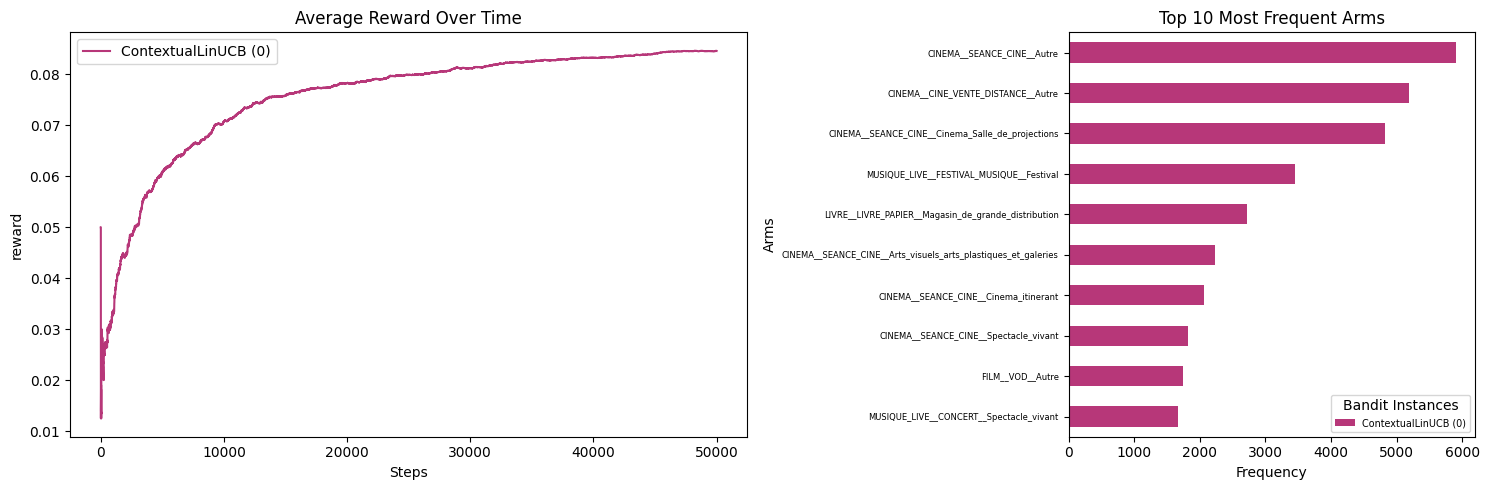

In [ ]:
tt_dataset.training_data = tt_dataset.user_data.head(50000)

large_boost_LinUCB = ContextualLinUCB(alpha=0.1, boost=100)
large_boost_LinUCB.train(tt_dataset, get_conversion_reward, context="user_embedding")

plot_bandit_performances([large_boost_LinUCB])